Instalación de dependencias para PISV

In [16]:

!pip install torch imagehash matplotlib


Modelo Base de Transmisión Semántica (JSCC) con Canal Ruidoso

Usando dispositivo: cpu
Cargando CIFAR-10...


100%|██████████| 170M/170M [00:10<00:00, 15.6MB/s]


¡Iniciando entrenamiento! (Espera unos minutos...)
Época [1/5], Loss: 0.0085
Época [2/5], Loss: 0.0025
Época [3/5], Loss: 0.0018
Época [4/5], Loss: 0.0015
Época [5/5], Loss: 0.0013
¡Entrenamiento completado!


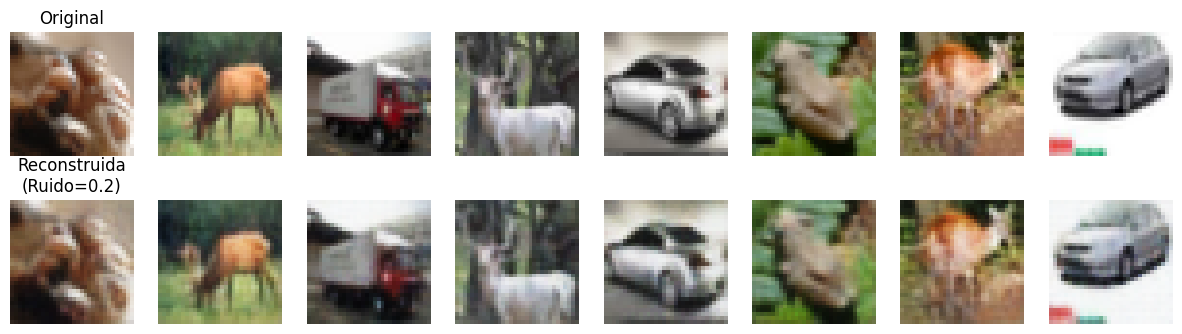

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt


# 1. Definición del 'Semantic Encoder' (Transmisor)

class SemanticEncoder(nn.Module):
    def __init__(self, channel_dim=128):
        super(SemanticEncoder, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(64, channel_dim, kernel_size=3, stride=2, padding=1)

        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm2d(64)
        self.bn3 = nn.BatchNorm2d(channel_dim)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.bn3(self.conv3(x))
        return x


# 2. Definición del 'Semantic Decoder' (Receptor)

class SemanticDecoder(nn.Module):
    def __init__(self, channel_dim=128):
        super(SemanticDecoder, self).__init__()
        self.deconv1 = nn.ConvTranspose2d(channel_dim, 64, kernel_size=3, stride=2, padding=1, output_padding=1)
        self.deconv2 = nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1)
        self.deconv3 = nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1)

        self.bn1 = nn.BatchNorm2d(64)
        self.bn2 = nn.BatchNorm2d(32)

    def forward(self, x):
        x = F.relu(self.bn1(self.deconv1(x)))
        x = F.relu(self.bn2(self.deconv2(x)))
        x = torch.sigmoid(self.deconv3(x))
        return x


# 3. Simulación del Canal (El Ruido)

class NoisyChannel(nn.Module):
    def __init__(self, noise_power=0.1):
        super(NoisyChannel, self).__init__()
        self.noise_power = noise_power

    def forward(self, x):
        noise = torch.randn_like(x) * self.noise_power
        return x + noise


# 4. Bloque Principal de Ejecución

if __name__ == "__main__":
    # --- Configuración ---
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Usando dispositivo: {device}")

    BATCH_SIZE = 128
    LEARNING_RATE = 0.001
    EPOCHS = 5
    NOISE_POWER = 0.2

    # --- Datos ---
    transform = transforms.Compose([transforms.ToTensor()])
    print("Cargando CIFAR-10...")
    train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=True)

    # --- Modelos ---
    encoder = SemanticEncoder().to(device)
    decoder = SemanticDecoder().to(device)
    channel = NoisyChannel(noise_power=NOISE_POWER).to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=LEARNING_RATE)

    # --- Entrenamiento ---
    print("¡Iniciando entrenamiento! (Espera unos minutos...)")
    for epoch in range(EPOCHS):
        running_loss = 0.0
        for images, _ in train_loader:
            images = images.to(device)

            # Forward
            encoded = encoder(images)
            noisy_encoded = channel(encoded)
            decoded = decoder(noisy_encoded)

            # Backward
            loss = criterion(decoded, images)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)
        print(f"Época [{epoch+1}/{EPOCHS}], Loss: {avg_loss:.4f}")

    print("¡Entrenamiento completado!")

    # --- Visualización ---
    encoder.eval()
    decoder.eval()

    # Tomar 8 imágenes de prueba
    images, _ = next(iter(test_loader))
    images = images.to(device)

    with torch.no_grad():
        encoded = encoder(images)
        noisy = channel(encoded)
        reconstructed = decoder(noisy)

    # Graficar
    fig, axes = plt.subplots(2, 8, figsize=(15, 4))
    for i in range(8):
        # Originales
        axes[0, i].imshow(images[i].cpu().permute(1, 2, 0))
        axes[0, i].axis('off')
        if i == 0: axes[0, i].set_title("Original")

        # Reconstruidas
        axes[1, i].imshow(reconstructed[i].cpu().permute(1, 2, 0))
        axes[1, i].axis('off')
        if i == 0: axes[1, i].set_title(f"Reconstruida\n(Ruido={NOISE_POWER})")

    plt.show()

Protocolo PISV: Detección de Alucinaciones mediante Hashing Perceptual


INICIANDO PROTOCOLO DE VERIFICACIÓN PISV

[CASO 1: Transmisión Normal]
Hash Original:     90e068e6e3651b93
Hash Reconstruido: 84e069e6e3611b83
Diferencia:        5
RESULTADO:         APROBADO (Semántica Preservada)

[CASO 2: Simulación de Alucinación (Avión -> Caballo)]
Hash Original (Avión):     90e068e6e3651b93
Hash Alucinado (Caballo):  c38717d3eb3c1367
Diferencia:                31
RESULTADO:                 ALERTA DE INTEGRIDAD: IMAGEN RECHAZADA


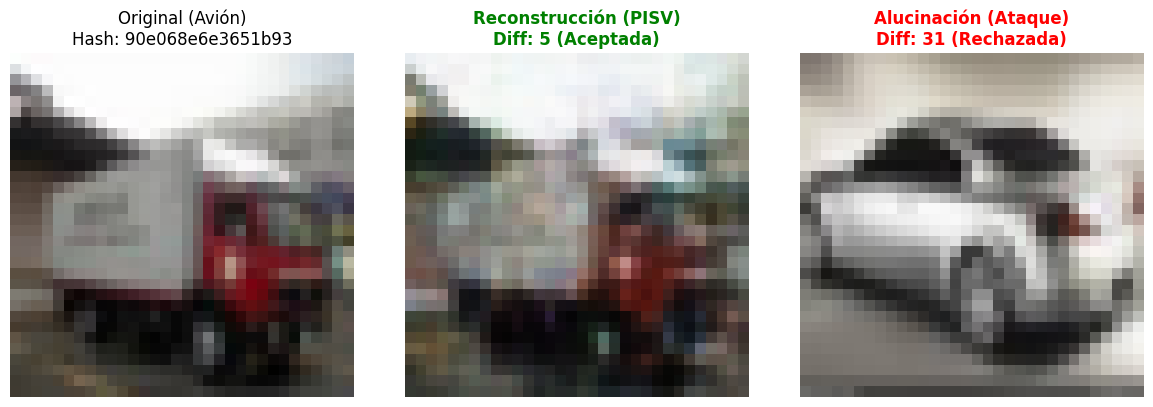

In [22]:
import imagehash
from PIL import Image
import numpy as np


def calcular_hash_perceptual(tensor_imagen):
    """
    Convierte un tensor de PyTorch a un Hash Perceptual (dHash).
    El dHash es robusto: resiste pequeños cambios (ruido, borrosidad)
    pero cambia drásticamente si la imagen es distinta semánticamente.
    """

    img_np = tensor_imagen.cpu().detach().permute(1, 2, 0).numpy()

    img_np = (img_np * 255).astype(np.uint8)
    img_pil = Image.fromarray(img_np)

    # Calcular dHash
    return imagehash.dhash(img_pil)

def verificar_integridad(imagen_original, imagen_reconstruida, umbral=10):
    """
    Compara los hashes y decide si la reconstrucción es confiable.
    """
    hash_orig = calcular_hash_perceptual(imagen_original)
    hash_rec = calcular_hash_perceptual(imagen_reconstruida)


    diferencia = hash_orig - hash_rec

    es_confiable = diferencia <= umbral
    return es_confiable, diferencia, hash_orig, hash_rec


#Simulación del Protocolo PISV

print("\nINICIANDO PROTOCOLO DE VERIFICACIÓN PISV")


img_real = images[2]



encoded = encoder(img_real.unsqueeze(0).to(device))
noisy = channel(encoded)
img_reconstruida = decoder(noisy).squeeze(0)

confiable, diff, h1, h2 = verificar_integridad(img_real, img_reconstruida)

print(f"\n[CASO 1: Transmisión Normal]")
print(f"Hash Original:     {h1}")
print(f"Hash Reconstruido: {h2}")
print(f"Diferencia:        {diff}")
print(f"RESULTADO:         {'APROBADO (Semántica Preservada)' if confiable else 'RECHAZADO'}")


#CASO DE ATAQUE / ALUCINACIÓN


img_alucinacion = images[4] # TomamosCABALLO/CIERVO

confiable_fake, diff_fake, h1_fake, h2_fake = verificar_integridad(img_real, img_alucinacion)

print(f"\n[CASO 2: Simulación de Alucinación (Avión -> Caballo)]")
print(f"Hash Original (Avión):     {h1_fake}")
print(f"Hash Alucinado (Caballo):  {h2_fake}")
print(f"Diferencia:                {diff_fake}")
print(f"RESULTADO:                 {'APROBADO' if confiable_fake else 'ALERTA DE INTEGRIDAD: IMAGEN RECHAZADA'}")


import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

# 1. Real
ax[0].imshow(img_real.detach().cpu().permute(1, 2, 0))
ax[0].set_title(f"Original (Avión)\nHash: {h1}")
ax[0].axis('off')

# 2. Reconstrucción PISV
ax[1].imshow(img_reconstruida.detach().cpu().permute(1, 2, 0))
color = 'green' if confiable else 'red'
ax[1].set_title(f"Reconstrucción (PISV)\nDiff: {diff} ({'Aceptada' if confiable else 'Rechazada'})", color=color, fontweight='bold')
ax[1].axis('off')

if confiable:
    for spine in ax[1].spines.values():
        spine.set_edgecolor('green')
        spine.set_linewidth(3)

# 3. Alucinación
ax[2].imshow(img_alucinacion.detach().cpu().permute(1, 2, 0))
color_fake = 'green' if confiable_fake else 'red'
ax[2].set_title(f"Alucinación (Ataque)\nDiff: {diff_fake} ({'Aceptada' if confiable_fake else 'Rechazada'})", color=color_fake, fontweight='bold')
ax[2].axis('off')

if not confiable_fake:
    for spine in ax[2].spines.values():
        spine.set_edgecolor('red')
        spine.set_linewidth(3)

plt.tight_layout()
plt.show()

Experimento 1: Evaluación de Rendimiento y Seguridad del Sistema

In [19]:

# Validación Estadística Masiva

import random

print("\nINICIANDO VALIDACIÓN ESTADÍSTICA (1000 Iteraciones)")

def ejecutar_test_masivo(num_muestras=1000, umbral=14):
    """
    Simula 1000 transmisiones y mide la precisión del sistema.
    """
    aciertos_legitimos = 0
    aciertos_ataque = 0
    falsos_positivos = 0
    falsos_negativos = 0
    # Dataset de prueba
    iter_test = iter(test_loader)

    for i in range(num_muestras):
        try:
            images, _ = next(iter_test)
        except StopIteration:
            iter_test = iter(test_loader)
            images, _ = next(iter_test)

        images = images.to(device)
        img_real = images[0]



        with torch.no_grad():
            encoded = encoder(img_real.unsqueeze(0))
            noisy = channel(encoded)
            reconstructed = decoder(noisy).squeeze(0)

        es_confiable, diff, _, _ = verificar_integridad(img_real, reconstructed, umbral)

        if es_confiable:
            aciertos_legitimos += 1
        else:
            falsos_positivos += 1

        # Ataque de Alucinación
        # Imagen diferente del dataset para simular alucinación
        idx_random = random.randint(1, len(images)-1)
        img_alucinada = images[idx_random] # Otra foto

        es_confiable_fake, diff_fake, _, _ = verificar_integridad(img_real, img_alucinada, umbral)

        if not es_confiable_fake:
            aciertos_ataque += 1
        else:
            falsos_negativos += 1

        if i % 100 == 0:
            print(f"Procesando muestra {i}/{num_muestras}...")

    # Calcular métricas finales
    total_intentos = num_muestras * 2 # Legítimos + Ataques
    total_aciertos = aciertos_legitimos + aciertos_ataque
    accuracy = (total_aciertos / total_intentos) * 100

    print("\nRESULTADOS")
    print(f"Precisión Total del Sistema: {accuracy:.2f}%")
    print("-" * 30)
    print(f"Transmisiones Legítimas Aceptadas: {aciertos_legitimos}/{num_muestras} (Robustez)")
    print(f"Ataques de Alucinación Detectados: {aciertos_ataque}/{num_muestras} (Seguridad)")
    print("-" * 30)
    print(f"Falsos Positivos (Rechazos incorrectos): {falsos_positivos}")
    print(f"Falsos Negativos (Alucinaciones no detectadas): {falsos_negativos}")

    return accuracy



precision = ejecutar_test_masivo(num_muestras=1000, umbral=14)


INICIANDO VALIDACIÓN ESTADÍSTICA (1000 Iteraciones)
Procesando muestra 0/1000...
Procesando muestra 100/1000...
Procesando muestra 200/1000...
Procesando muestra 300/1000...
Procesando muestra 400/1000...
Procesando muestra 500/1000...
Procesando muestra 600/1000...
Procesando muestra 700/1000...
Procesando muestra 800/1000...
Procesando muestra 900/1000...

RESULTADOS
Precisión Total del Sistema: 93.90%
------------------------------
Transmisiones Legítimas Aceptadas: 878/1000 (Robustez)
Ataques de Alucinación Detectados: 1000/1000 (Seguridad)
------------------------------
Falsos Positivos (Rechazos incorrectos): 122
Falsos Negativos (Alucinaciones no detectadas): 0


Experimento 2: Test de estrés

Ruido Sigma=0.1 -> Robustez: 100.0% | Seguridad: 100.0%
Ruido Sigma=0.2 -> Robustez: 100.0% | Seguridad: 100.0%
Ruido Sigma=0.3 -> Robustez: 100.0% | Seguridad: 100.0%
Ruido Sigma=0.4 -> Robustez: 98.0% | Seguridad: 100.0%
Ruido Sigma=0.5 -> Robustez: 96.0% | Seguridad: 100.0%
Ruido Sigma=0.6 -> Robustez: 98.0% | Seguridad: 100.0%
Ruido Sigma=0.7 -> Robustez: 91.0% | Seguridad: 100.0%
Ruido Sigma=0.8 -> Robustez: 93.0% | Seguridad: 100.0%
Ruido Sigma=0.9 -> Robustez: 95.0% | Seguridad: 100.0%
Ruido Sigma=1.0 -> Robustez: 80.0% | Seguridad: 100.0%


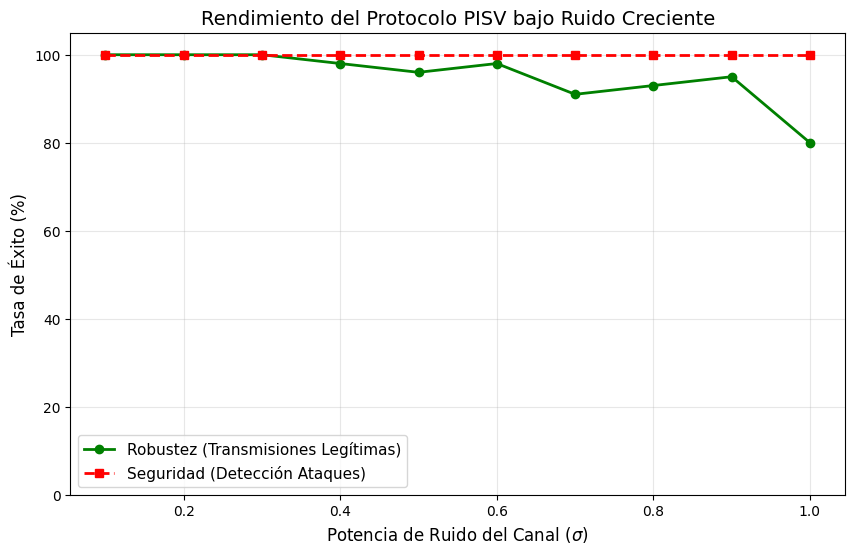

In [20]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import random
import imagehash
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


def calcular_hash_perceptual(tensor_imagen):

    img_np = tensor_imagen.cpu().detach().permute(1, 2, 0).numpy()
    img_np = (img_np * 255).astype(np.uint8)
    img_pil = Image.fromarray(img_np)
    return imagehash.dhash(img_pil)

def verificar_integridad(imagen_original, imagen_reconstruida, umbral=14):
    h1 = calcular_hash_perceptual(imagen_original)
    h2 = calcular_hash_perceptual(imagen_reconstruida)
    return (h1 - h2) <= umbral, (h1 - h2), h1, h2

if 'test_loader' not in globals():
    print("Recargando dataset de prueba...")
    transform = transforms.Compose([transforms.ToTensor()])
    test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=True)

if 'encoder' not in globals() or 'decoder' not in globals():
    raise RuntimeError("ERROR CRÍTICO: No se encontraron los modelos 'encoder' y 'decoder'. \n"
                       "Por favor, vuelve a ejecutar el bloque de ENTRENAMIENTO (Fase 1) primero para que la IA aprenda.")

# Lógica del Test de Estrés
def ejecutar_stress_test(niveles_ruido, muestras_por_nivel=100):
    tasa_aceptacion_legitima = []
    tasa_deteccion_ataques = []


    iter_test = iter(test_loader)

    for sigma in niveles_ruido:

        channel.noise_power = sigma

        aciertos_leg = 0
        aciertos_att = 0

        for _ in range(muestras_por_nivel):

            try:
                images, _ = next(iter_test)
            except StopIteration:
                iter_test = iter(test_loader)
                images, _ = next(iter_test)

            images = images.to(device)
            img_real = images[0]

            # Test Legítimo
            with torch.no_grad():
                encoded = encoder(img_real.unsqueeze(0))
                noisy = channel(encoded)
                reconstructed = decoder(noisy).squeeze(0)


            es_confiable, _, _, _ = verificar_integridad(img_real, reconstructed, umbral=14)
            if es_confiable: aciertos_leg += 1

            # Test Ataque
            idx_random = random.randint(1, len(images)-1)
            img_fake = images[idx_random]
            es_confiable_fake, _, _, _ = verificar_integridad(img_real, img_fake, umbral=14)
            if not es_confiable_fake: aciertos_att += 1


        acc_leg = (aciertos_leg / muestras_por_nivel) * 100
        acc_att = (aciertos_att / muestras_por_nivel) * 100

        tasa_aceptacion_legitima.append(acc_leg)
        tasa_deteccion_ataques.append(acc_att)

        print(f"Ruido Sigma={sigma:.1f} -> Robustez: {acc_leg:.1f}% | Seguridad: {acc_att:.1f}%")

    return tasa_aceptacion_legitima, tasa_deteccion_ataques


niveles_ruido = np.linspace(0.1, 1.0, 10)
curva_legitima, curva_ataques = ejecutar_stress_test(niveles_ruido)

plt.figure(figsize=(10, 6))
plt.plot(niveles_ruido, curva_legitima, 'o-', label='Robustez (Transmisiones Legítimas)', color='green', linewidth=2)
plt.plot(niveles_ruido, curva_ataques, 's--', label='Seguridad (Detección Ataques)', color='red', linewidth=2)

plt.title('Rendimiento del Protocolo PISV bajo Ruido Creciente', fontsize=14)
plt.xlabel(r'Potencia de Ruido del Canal ($\sigma$)', fontsize=12)
plt.ylabel('Tasa de Éxito (%)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.ylim(0, 105)

plt.savefig('fig_stress_test.png')
plt.show()

Experimento 3: Comparativa de umbrales (Trade-off)

In [21]:

import time
import torch.nn.functional as F

print("\n=== ANÁLISIS DE TRADE-OFF: ROBUSTEZ VS SEGURIDAD ADVERSARIA ===")

# Función de Ataque (FGSM)
def generar_ataque_fgsm(imagen, epsilon=0.05):
    imagen_clone = imagen.clone().detach().requires_grad_(True)
    encoded = encoder(imagen_clone.unsqueeze(0))
    decoded = decoder(channel(encoded))
    loss = F.mse_loss(decoded, imagen_clone.unsqueeze(0))
    encoder.zero_grad()
    decoder.zero_grad()
    loss.backward()
    data_grad = imagen_clone.grad.data
    perturbed_image = imagen + epsilon * data_grad.sign()
    return torch.clamp(perturbed_image, 0, 1)


def test_comparativo(muestras=200):

    configuraciones = [
        {"nombre": "Tolerante (Alta Disponibilidad)", "umbral": 14},
        {"nombre": "Estricto (Alta Seguridad)", "umbral": 2}
    ]

    iter_test = iter(test_loader)

    batch_imagenes = []
    for _ in range(muestras):
        try:
            img, _ = next(iter_test)
        except StopIteration:
            iter_test = iter(test_loader)
            img, _ = next(iter_test)
        batch_imagenes.append(img[0].to(device))

    print(f"Evaluando {muestras} muestras en ambos modos...")
    print("-" * 60)
    print(f"{'MODO':<30} | {'LATENCIA':<10} | {'DEFENSA (FGSM)':<15}")
    print("-" * 60)

    resultados_tex = []

    for config in configuraciones:
        umbral = config["umbral"]
        ataques_detectados = 0
        tiempos = []

        for img_real in batch_imagenes:
            # Medir Latencia
            start = time.time()
            with torch.no_grad():
                encoded = encoder(img_real.unsqueeze(0))
                rec = decoder(channel(encoded)).squeeze(0)
            verificar_integridad(img_real, rec, umbral)
            end = time.time()
            tiempos.append((end - start)*1000)

            # Medir Seguridad
            img_atacada = generar_ataque_fgsm(img_real, epsilon=0.05)
            with torch.no_grad():
                encoded_atk = encoder(img_atacada.unsqueeze(0))
                rec_atk = decoder(channel(encoded_atk)).squeeze(0)

            es_seguro, _, _, _ = verificar_integridad(img_real, rec_atk, umbral)
            if not es_seguro:
                ataques_detectados += 1

        avg_lat = sum(tiempos)/len(tiempos)
        tasa_def = (ataques_detectados/muestras)*100

        print(f"{config['nombre']:<30} | {avg_lat:.2f} ms    | {tasa_def:.1f}%")
        resultados_tex.append((config['nombre'], avg_lat, tasa_def))

    return resultados_tex

resultados = test_comparativo()


=== ANÁLISIS DE TRADE-OFF: ROBUSTEZ VS SEGURIDAD ADVERSARIA ===
Evaluando 200 muestras en ambos modos...
------------------------------------------------------------
MODO                           | LATENCIA   | DEFENSA (FGSM) 
------------------------------------------------------------
Tolerante (Alta Disponibilidad) | 1.60 ms    | 18.0%
Estricto (Alta Seguridad)      | 1.55 ms    | 99.5%
